# You Only Look Once: Unified, Real-Time Object Detection (YOLO)

**Paper:** [arXiv:1506.02640](https://arxiv.org/abs/1506.02640)
**Authors:** Joseph Redmon, Santosh Divvala, Ross Girshick, Ali Farhadi (2015; CVPR 2016)

This notebook implements a simplified YOLO (v1) object detector from scratch in PyTorch.
YOLO reframes object detection as a single regression problem: one neural network pass
predicts all bounding boxes and class probabilities at once.

**Simplifications vs the paper:**
- Synthetic dataset (colored shapes on black) instead of PASCAL VOC, with fresh random images every epoch
- B=1 box per cell (paper uses B=2)
- 3 classes instead of 20
- 10 conv layers instead of 24, with BatchNorm (BatchNorm came later, in YOLOv2; it makes training from scratch faster and steadier)
- 224×224 input instead of 448×448
- 20 epochs with Adam instead of ~135 epochs with SGD, and no ImageNet pretraining

## 1. Imports & Configuration

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import random
import time

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters ---
S = 7          # Grid size (7x7)
B = 1          # Boxes per cell (simplified)
C = 3          # Number of classes (circle, rectangle, triangle)
IMG_SIZE = 224 # Input image size
LAMBDA_COORD = 5.0    # Weight for localization loss (as in the paper)
LAMBDA_NOOBJ = 0.5    # Weight for no-object confidence loss (as in the paper)
BATCH_SIZE = 32
EPOCHS = 20
TRAIN_PER_EPOCH = 3000  # fresh synthetic images per epoch
TEST_SIZE = 200         # fixed test images (never seen in training)
LR = 1e-3
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

Device: cpu


## 2. Synthetic Dataset

We generate images with randomly placed colored shapes (red circles, green rectangles, blue triangles) on a black background. Each image contains 1-3 shapes with bounding box annotations.

- **Seeded per image:** image `idx` is always drawn the same way, so the test set is fixed and results are reproducible.
- **Fresh training images every epoch:** the training set draws new images each epoch (3,000 per epoch), so the model cannot just memorize a few hundred pictures.
- **One object per grid cell:** shapes don't overlap, and no two shapes have their centers in the same cell. YOLO v1 with B=1 can only predict one object per cell, so a second object in a cell would be a label the model can never get right.

**Target encoding per grid cell (8 values):**
`[confidence, x_offset, y_offset, w, h, class_0, class_1, class_2]`
`x_offset, y_offset` are the box center's position inside its cell (0 to 1); `w, h` are relative to the whole image.

Train: 3000 new images per epoch x 20 epochs, Test: 200 fixed images


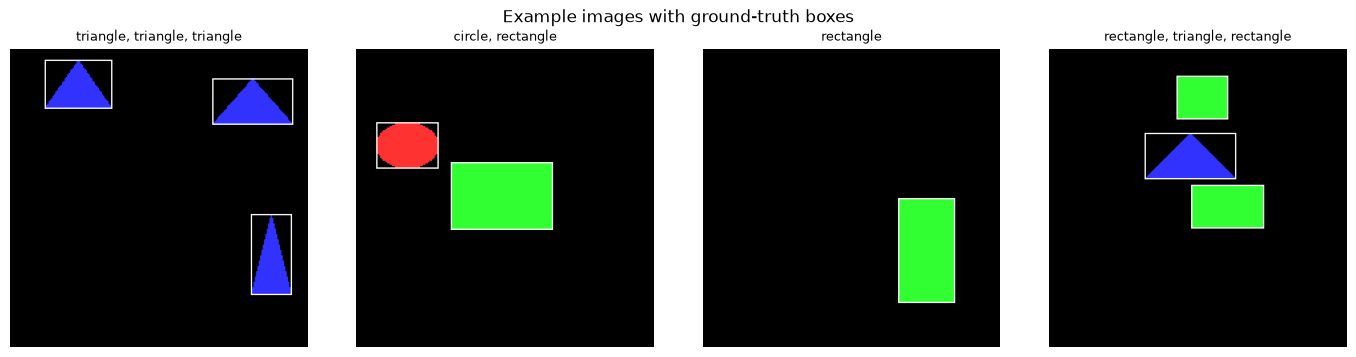

In [2]:
CLASS_NAMES = ['circle', 'rectangle', 'triangle']
CLASS_COLORS = [(255, 50, 50), (50, 255, 50), (50, 50, 255)]

class ShapeDataset(Dataset):
    """Synthetic shapes. Image `idx` is generated from its own seed, so it is always the same."""
    def __init__(self, num_samples, seed, img_size=224, S=7, B=1, C=3):
        self.num_samples = num_samples
        self.seed = seed
        self.img_size = img_size
        self.S = S
        self.B = B
        self.C = C
        self.cell_size = img_size / S

    def __len__(self):
        return self.num_samples

    def make_image(self, idx):
        """Return (PIL image, list of boxes (x1, y1, x2, y2, class_id))."""
        rng = random.Random(self.seed * 1_000_003 + idx)
        img = Image.new('RGB', (self.img_size, self.img_size), (0, 0, 0))
        draw = ImageDraw.Draw(img)
        boxes, used_cells = [], set()
        for _ in range(rng.randint(1, 3)):
            for _attempt in range(50):
                cls_id = rng.randint(0, self.C - 1)
                w, h = rng.randint(30, 80), rng.randint(30, 80)
                cx = rng.randint(w // 2 + 5, self.img_size - w // 2 - 5)
                cy = rng.randint(h // 2 + 5, self.img_size - h // 2 - 5)
                x1, y1, x2, y2 = cx - w // 2, cy - h // 2, cx + w // 2, cy + h // 2
                cell = (min(int(cy / self.cell_size), self.S - 1), min(int(cx / self.cell_size), self.S - 1))
                overlaps = any(not (x2 < b[0] or x1 > b[2] or y2 < b[1] or y1 > b[3]) for b in boxes)
                if not overlaps and cell not in used_cells:
                    break
            else:
                continue  # no free spot found; skip this shape
            used_cells.add(cell)
            color = CLASS_COLORS[cls_id]
            if cls_id == 0:    # circle
                draw.ellipse([x1, y1, x2, y2], fill=color)
            elif cls_id == 1:  # rectangle
                draw.rectangle([x1, y1, x2, y2], fill=color)
            else:              # triangle
                draw.polygon([(cx, y1), (x1, y2), (x2, y2)], fill=color)
            boxes.append((x1, y1, x2, y2, cls_id))
        return img, boxes

    def __getitem__(self, idx):
        img, boxes = self.make_image(idx)
        img_tensor = torch.from_numpy(np.array(img, dtype=np.float32) / 255.0).permute(2, 0, 1)  # HWC -> CHW

        # Build target tensor: (S, S, 5*B + C)
        target = torch.zeros(self.S, self.S, 5 * self.B + self.C)
        for (x1, y1, x2, y2, cls_id) in boxes:
            cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
            w, h = x2 - x1, y2 - y1
            grid_x = min(int(cx / self.cell_size), self.S - 1)
            grid_y = min(int(cy / self.cell_size), self.S - 1)
            target[grid_y, grid_x, 0] = 1.0                            # confidence
            target[grid_y, grid_x, 1] = cx / self.cell_size - grid_x   # x offset in cell
            target[grid_y, grid_x, 2] = cy / self.cell_size - grid_y   # y offset in cell
            target[grid_y, grid_x, 3] = w / self.img_size              # width
            target[grid_y, grid_x, 4] = h / self.img_size              # height
            target[grid_y, grid_x, 5 + cls_id] = 1.0                   # class one-hot
        return img_tensor, target


class TrainShapeDataset(ShapeDataset):
    """Training set: set `.epoch` before each epoch to get a fresh batch of images."""
    epoch = 0
    def make_image(self, idx):
        return super().make_image(idx + self.epoch * self.num_samples)


train_ds = TrainShapeDataset(TRAIN_PER_EPOCH, seed=SEED, img_size=IMG_SIZE, S=S, B=B, C=C)
test_ds = ShapeDataset(TEST_SIZE, seed=SEED + 1, img_size=IMG_SIZE, S=S, B=B, C=C)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
print(f"Train: {len(train_ds)} new images per epoch x {EPOCHS} epochs, Test: {len(test_ds)} fixed images")

# Show a few training images with their ground-truth boxes
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, idx in zip(axes, range(4)):
    img, boxes = test_ds.make_image(idx)
    draw = ImageDraw.Draw(img)
    for (x1, y1, x2, y2, cls_id) in boxes:
        draw.rectangle([x1, y1, x2, y2], outline=(255, 255, 255), width=1)
    ax.imshow(img)
    ax.set_title(', '.join(CLASS_NAMES[b[4]] for b in boxes), fontsize=9)
    ax.axis('off')
plt.suptitle('Example images with ground-truth boxes', fontsize=12)
plt.tight_layout()
plt.show()

## 3. YOLO Network Architecture

A scaled-down version of the paper's network: a stack of 3×3 convolutions with 1×1 "reduction" layers in between (the paper took this idea from GoogLeNet / Network-in-Network), max-pooling to shrink the image from 224×224 down to the 7×7 grid, then 2 fully connected layers.

- Leaky ReLU (slope 0.1) after every hidden layer, as in the paper
- Dropout 0.5 after the first fully connected layer, as in the paper
- **BatchNorm after each conv** (not in YOLOv1; added in YOLOv2). It makes training from scratch, without ImageNet pretraining, much faster and steadier.
- The paper's last layer is linear; we put a **sigmoid** on it so every output (confidence, offsets, sizes, class scores) is between 0 and 1, which matches our targets.

The output is reshaped to (S, S, 5*B + C) = (7, 7, 8).

In [3]:
def conv_block(c_in, c_out, k):
    return [nn.Conv2d(c_in, c_out, k, padding=k // 2, bias=False),
            nn.BatchNorm2d(c_out),
            nn.LeakyReLU(0.1)]

class YOLONet(nn.Module):
    def __init__(self, S=7, B=1, C=3):
        super().__init__()
        self.S, self.B, self.C = S, B, C
        self.output_dim = 5 * B + C  # 8

        # --- Conv backbone: 224x224 -> 7x7 ---
        self.features = nn.Sequential(
            *conv_block(3, 16, 3), nn.MaxPool2d(2),                               # -> 112
            *conv_block(16, 32, 3), nn.MaxPool2d(2),                              # -> 56
            *conv_block(32, 16, 1), *conv_block(16, 64, 3), nn.MaxPool2d(2),      # -> 28
            *conv_block(64, 32, 1), *conv_block(32, 128, 3), nn.MaxPool2d(2),     # -> 14
            *conv_block(128, 64, 1), *conv_block(64, 256, 3), nn.MaxPool2d(2),    # -> 7
            *conv_block(256, 128, 1), *conv_block(128, 256, 3),                   # 7x7x256
        )

        # --- Detection head ---
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * S * S, 512),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.5),
            nn.Linear(512, S * S * self.output_dim),
        )

    def forward(self, x):
        x = self.features(x)            # (batch, 256, 7, 7)
        x = self.head(x)                # (batch, 7*7*8)
        x = torch.sigmoid(x)            # all outputs in [0, 1]
        return x.view(-1, self.S, self.S, self.output_dim)  # (batch, 7, 7, 8)

model = YOLONet(S=S, B=B, C=C).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
conv_layers = sum(isinstance(m, nn.Conv2d) for m in model.modules())
print(f"Conv layers: {conv_layers}, total parameters: {total_params:,}")

Conv layers: 10, total parameters: 7,163,128


## 4. YOLO Loss Function

Implements the multi-part sum-squared-error loss from the paper (Equation 3):

1. **Coordinate loss** (λ_coord = 5): penalizes x, y, √w, √h errors at cells containing objects
2. **Object confidence loss**: pushes confidence toward 1 at cells with objects (the paper's target is the IoU between the predicted and true box; we use 1 for simplicity)
3. **No-object confidence loss** (λ_noobj = 0.5): pushes confidence toward 0 at empty cells
4. **Classification loss**: penalizes class-probability errors at cells with objects

The loss is summed over cells and averaged over the batch.

In [4]:
class YOLOLoss(nn.Module):
    def __init__(self, lambda_coord=5.0, lambda_noobj=0.5):
        super().__init__()
        self.lambda_coord = lambda_coord
        self.lambda_noobj = lambda_noobj

    def forward(self, pred, target):
        # pred, target: (batch, S, S, 5*B + C)
        obj_mask = target[..., 0] > 0.5   # cells that contain an object center
        noobj_mask = ~obj_mask
        sse = lambda a, b: ((a - b) ** 2).sum()

        # 1. Coordinates: x, y offsets and square roots of w, h
        coord_loss = sse(pred[..., 1:3][obj_mask], target[..., 1:3][obj_mask]) + \
                     sse(pred[..., 3:5][obj_mask].clamp(min=1e-8).sqrt(), target[..., 3:5][obj_mask].sqrt())
        # 2-3. Confidence at object / empty cells
        obj_conf_loss = sse(pred[..., 0][obj_mask], target[..., 0][obj_mask])
        noobj_conf_loss = sse(pred[..., 0][noobj_mask], target[..., 0][noobj_mask])
        # 4. Class probabilities at object cells
        cls_loss = sse(pred[..., 5:][obj_mask], target[..., 5:][obj_mask])

        n = pred.size(0)
        total = (self.lambda_coord * coord_loss + obj_conf_loss
                 + self.lambda_noobj * noobj_conf_loss + cls_loss) / n
        parts = {'coord': coord_loss.item() / n, 'obj': obj_conf_loss.item() / n,
                 'noobj': noobj_conf_loss.item() / n, 'cls': cls_loss.item() / n}
        return total, parts

criterion = YOLOLoss(lambda_coord=LAMBDA_COORD, lambda_noobj=LAMBDA_NOOBJ)

## 5. Intersection-over-Union (IoU) and Non-Maximal Suppression

IoU measures how much two boxes overlap (1 = identical, 0 = no overlap). Non-maximal suppression (NMS) keeps the highest-scoring box and drops other boxes of the same class that overlap it too much.

In [5]:
def compute_iou(box1, box2):
    # IoU between two boxes in (x1, y1, x2, y2, ...) format
    inter_w = max(0, min(box1[2], box2[2]) - max(box1[0], box2[0]))
    inter_h = max(0, min(box1[3], box2[3]) - max(box1[1], box2[1]))
    inter = inter_w * inter_h
    union = (box1[2] - box1[0]) * (box1[3] - box1[1]) + (box2[2] - box2[0]) * (box2[3] - box2[1]) - inter
    return inter / union if union > 0 else 0.0

def non_max_suppression(dets, iou_threshold=0.4):
    # dets: list of (x1, y1, x2, y2, class_id, score)
    dets = sorted(dets, key=lambda d: d[5], reverse=True)
    keep = []
    for d in dets:
        if all(d[4] != k[4] or compute_iou(d, k) < iou_threshold for k in keep):
            keep.append(d)
    return keep

## 6. Decoding Predictions

Convert the network's (S, S, 8) output into boxes. As in the paper, each box's score is **confidence × class probability**; boxes below a score threshold are dropped, then NMS removes duplicates.

In [6]:
def decode_prediction(pred, S=7, C=3, score_thresh=0.2, img_size=224):
    # pred: (S, S, 5*B + C) numpy array -> list of (x1, y1, x2, y2, class_id, score)
    cell_size = img_size / S
    dets = []
    for gy in range(S):
        for gx in range(S):
            class_probs = pred[gy, gx, 5:5 + C]
            cls_id = int(np.argmax(class_probs))
            score = float(pred[gy, gx, 0] * class_probs[cls_id])
            if score < score_thresh:
                continue
            cx = (gx + pred[gy, gx, 1]) * cell_size
            cy = (gy + pred[gy, gx, 2]) * cell_size
            bw, bh = pred[gy, gx, 3] * img_size, pred[gy, gx, 4] * img_size
            dets.append((cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2, cls_id, score))
    return non_max_suppression(dets, iou_threshold=0.4)

## 7. Evaluation: mAP@0.5

We measure detection quality the standard way, with **average precision (AP) at IoU 0.5**, the same kind of metric as the paper's PASCAL VOC mAP:

- A detection counts as correct if it has the right class and overlaps an unmatched ground-truth box with IoU ≥ 0.5.
- For each class, we rank detections by score and compute precision vs recall; AP is the (11-point) area under that curve. **mAP** is the mean over the 3 classes.

We also report **recall at score ≥ 0.2**: the share of real shapes that get a correct box (right class, IoU ≥ 0.5) above the threshold we use for the pictures.

In [7]:
def evaluate(model, dataset, score_thresh=0.2):
    model.eval()
    detections = {c: [] for c in range(C)}   # class -> list of (score, is_true_positive)
    n_gt = {c: 0 for c in range(C)}
    found, total_gt = 0, 0
    with torch.no_grad():
        for i in range(len(dataset)):
            img, _ = dataset[i]
            _, gt_boxes = dataset.make_image(i)
            pred = model(img.unsqueeze(0).to(DEVICE))[0].cpu().numpy()
            dets = decode_prediction(pred, S=S, C=C, score_thresh=0.01, img_size=IMG_SIZE)

            for g in gt_boxes:
                n_gt[g[4]] += 1
                total_gt += 1
                if any(d[4] == g[4] and d[5] >= score_thresh and compute_iou(d, g) >= 0.5 for d in dets):
                    found += 1

            matched = set()
            for d in dets:  # already sorted by score
                best_iou, best_j = 0.0, -1
                for j, g in enumerate(gt_boxes):
                    if g[4] == d[4] and j not in matched:
                        iou = compute_iou(d, g)
                        if iou > best_iou:
                            best_iou, best_j = iou, j
                is_tp = best_iou >= 0.5
                if is_tp:
                    matched.add(best_j)
                detections[d[4]].append((d[5], is_tp))

    aps = []
    for c in range(C):
        dets_c = sorted(detections[c], key=lambda x: -x[0])
        tp = np.cumsum([t for _, t in dets_c])
        fp = np.cumsum([not t for _, t in dets_c])
        recall = tp / max(n_gt[c], 1)
        precision = tp / np.maximum(tp + fp, 1)
        ap = np.mean([precision[recall >= r].max() if (recall >= r).any() else 0.0
                      for r in np.linspace(0, 1, 11)])
        aps.append(ap)
    model.train()
    return float(np.mean(aps)), aps, found / max(total_gt, 1)

mAP, aps, recall = evaluate(model, test_ds)
print(f"Before training: mAP@0.5 = {mAP:.3f}, recall = {recall:.3f}")

Before training: mAP@0.5 = 0.000, recall = 0.005


## 8. Training Loop

Adam (lr 1e-3) with a cosine learning-rate decay over 20 epochs. Every epoch uses 3,000 new synthetic images. We check mAP on the fixed test set every 5 epochs.

In [8]:
optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
history = {'loss': [], 'coord': [], 'obj': [], 'noobj': [], 'cls': [], 'map_epoch': [], 'map': []}
start = time.time()

for epoch in range(1, EPOCHS + 1):
    train_ds.epoch = epoch  # fresh images
    model.train()
    sums = {'loss': 0.0, 'coord': 0.0, 'obj': 0.0, 'noobj': 0.0, 'cls': 0.0}
    n_batches = 0
    for imgs, targets in train_loader:
        imgs, targets = imgs.to(DEVICE), targets.to(DEVICE)
        loss, parts = criterion(model(imgs), targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        sums['loss'] += loss.item()
        for k, v in parts.items():
            sums[k] += v
        n_batches += 1
    scheduler.step()
    for k in sums:
        history[k].append(sums[k] / n_batches)

    msg = (f"Epoch [{epoch:2d}/{EPOCHS}]  loss {history['loss'][-1]:.3f}  "
           f"(coord {history['coord'][-1]:.3f}, obj {history['obj'][-1]:.3f}, "
           f"noobj {history['noobj'][-1]:.3f}, cls {history['cls'][-1]:.3f})")
    if epoch % 5 == 0:
        mAP, _, _ = evaluate(model, test_ds)
        history['map_epoch'].append(epoch)
        history['map'].append(mAP)
        msg += f"  | test mAP@0.5 {mAP:.3f}"
    print(msg + f"  [{time.time() - start:.0f}s]")

print("Training complete!")

Epoch [ 1/20]  loss 5.174  (coord 0.440, obj 1.255, noobj 0.893, cls 1.274)  [53s]


Epoch [ 2/20]  loss 2.962  (coord 0.227, obj 0.671, noobj 0.682, cls 0.813)  [100s]


Epoch [ 3/20]  loss 1.991  (coord 0.179, obj 0.465, noobj 0.517, cls 0.375)  [147s]


Epoch [ 4/20]  loss 1.600  (coord 0.150, obj 0.383, noobj 0.423, cls 0.255)  [194s]


Epoch [ 5/20]  loss 1.302  (coord 0.127, obj 0.313, noobj 0.354, cls 0.178)  | test mAP@0.5 0.600  [242s]


...

Epoch [16/20]  loss 0.468  (coord 0.057, obj 0.068, noobj 0.127, cls 0.053)  [763s]


Epoch [17/20]  loss 0.440  (coord 0.054, obj 0.062, noobj 0.120, cls 0.050)  [810s]


Epoch [18/20]  loss 0.424  (coord 0.051, obj 0.063, noobj 0.110, cls 0.049)  [857s]


Epoch [19/20]  loss 0.428  (coord 0.052, obj 0.063, noobj 0.110, cls 0.050)  [904s]


Epoch [20/20]  loss 0.406  (coord 0.050, obj 0.054, noobj 0.113, cls 0.045)  | test mAP@0.5 0.903  [951s]
Training complete!


## 9. Training Curves

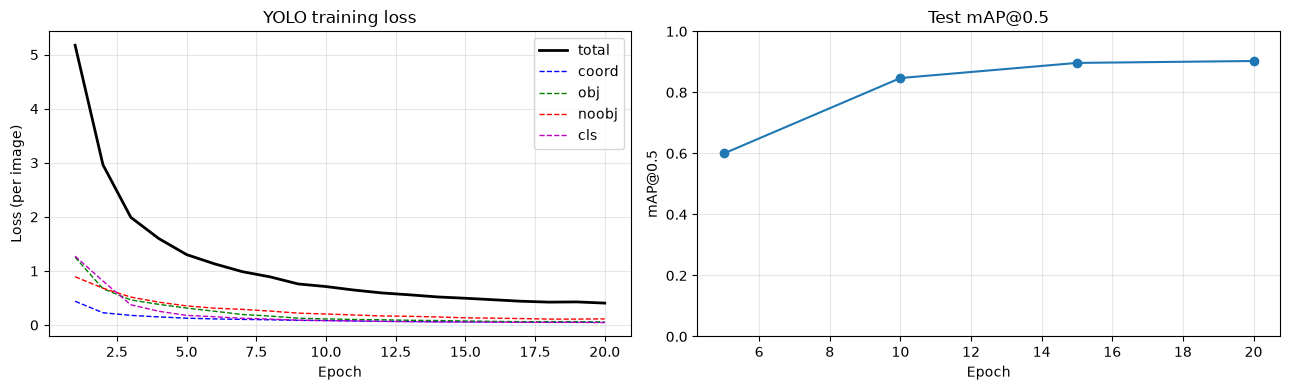

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
epochs_axis = range(1, EPOCHS + 1)
axes[0].plot(epochs_axis, history['loss'], 'k-', linewidth=2, label='total')
for k, style in [('coord', 'b--'), ('obj', 'g--'), ('noobj', 'r--'), ('cls', 'm--')]:
    axes[0].plot(epochs_axis, history[k], style, linewidth=1, label=k)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss (per image)')
axes[0].set_title('YOLO training loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(history['map_epoch'], history['map'], 'o-')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('mAP@0.5'); axes[1].set_ylim(0, 1)
axes[1].set_title('Test mAP@0.5'); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Detection Visualization

Predicted boxes (score ≥ 0.2) on test images the model never trained on. The label shows the class and score.

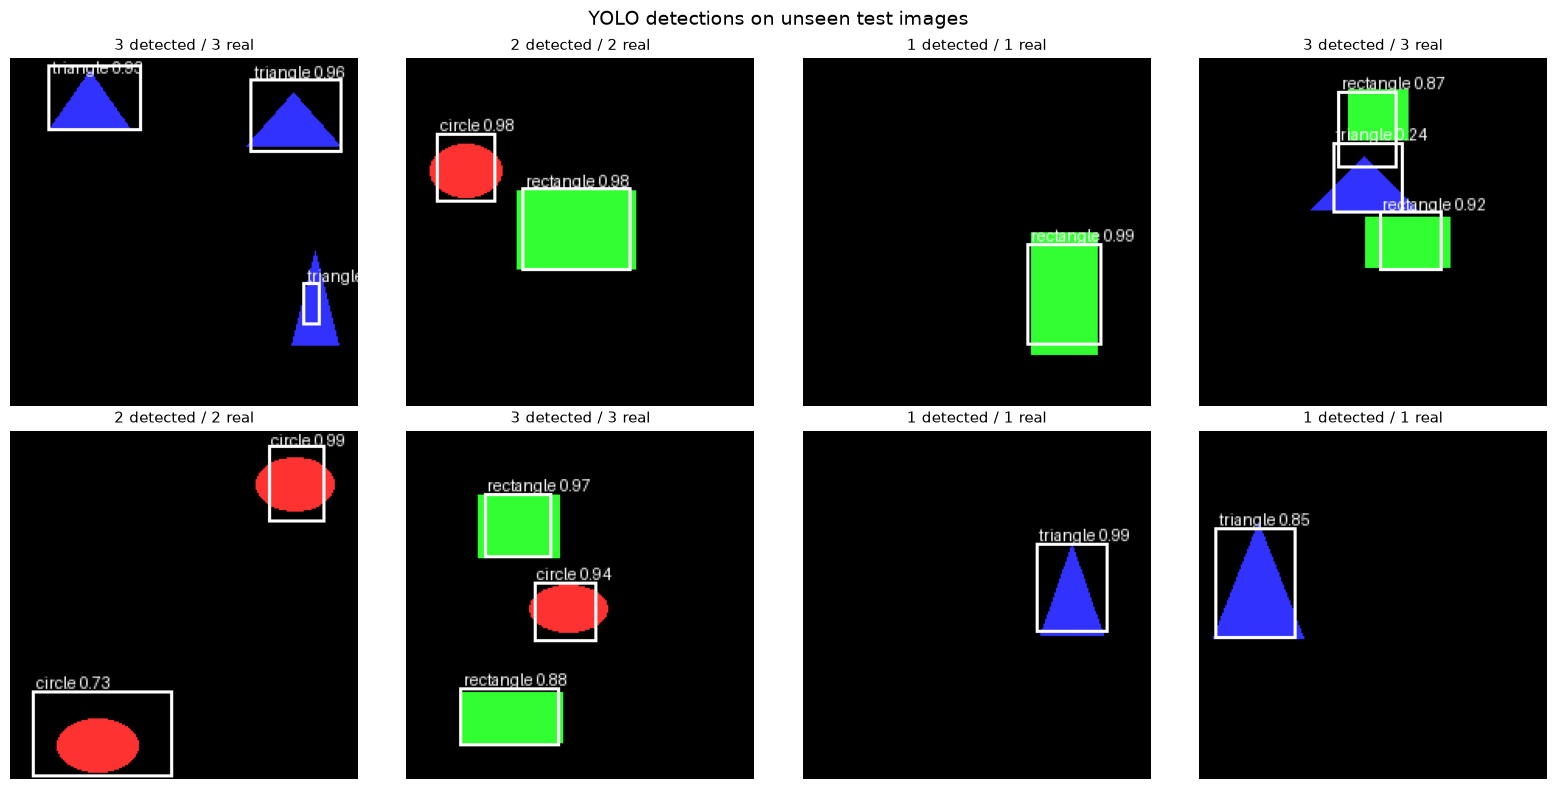

In [10]:
def draw_detections(img_tensor, detections):
    img = (img_tensor.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    pil_img = Image.fromarray(img)
    draw = ImageDraw.Draw(pil_img)
    for (x1, y1, x2, y2, cls_id, score) in detections:
        draw.rectangle([x1, y1, x2, y2], outline=(255, 255, 255), width=2)
        draw.text((x1 + 2, max(0, y1 - 11)), f"{CLASS_NAMES[cls_id]} {score:.2f}", fill=(255, 255, 255))
    return pil_img

model.eval()
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
with torch.no_grad():
    for ax, i in zip(axes.flatten(), range(8)):
        img, _ = test_ds[i]
        _, gt_boxes = test_ds.make_image(i)
        pred = model(img.unsqueeze(0).to(DEVICE))[0].cpu().numpy()
        dets = decode_prediction(pred, S=S, C=C, score_thresh=0.2, img_size=IMG_SIZE)
        ax.imshow(draw_detections(img, dets))
        ax.set_title(f'{len(dets)} detected / {len(gt_boxes)} real', fontsize=11)
        ax.axis('off')
plt.suptitle('YOLO detections on unseen test images', fontsize=14)
plt.tight_layout()
plt.show()

## 11. Final Evaluation

In [11]:
mAP, aps, recall = evaluate(model, test_ds)
print(f"Test images: {len(test_ds)}")
for name, ap in zip(CLASS_NAMES, aps):
    print(f"  AP@0.5 {name:9s}: {ap:.3f}")
print(f"mAP@0.5: {mAP:.3f}")
print(f"Recall (correct box with score >= 0.2): {recall:.3f}")
print(f"Total parameters: {total_params:,}")

Test images: 200
  AP@0.5 circle   : 0.908
  AP@0.5 rectangle: 0.906
  AP@0.5 triangle : 0.894
mAP@0.5: 0.903
Recall (correct box with score >= 0.2): 0.960
Total parameters: 7,163,128


## Summary

This notebook implemented a simplified YOLO (v1) object detector from scratch:

- **Grid-based detection:** a 7×7 grid where each cell predicts 1 bounding box, a confidence and 3 class probabilities
- **Single forward pass:** one network evaluation produces all detections for an image
- **Multi-part loss:** coordinates (λ_coord = 5), object and no-object confidence (λ_noobj = 0.5), and classification, as in the paper
- **Square-root width/height** so errors on small boxes count more
- **Non-maximal suppression** to remove duplicate boxes
- **mAP@0.5 evaluation** on 200 test images the model never trained on

### What the run above shows

- **It works as a detector on this toy task.** Test mAP@0.5 goes from 0.0 before training to about 0.60 after 5 epochs, 0.85 after 10, and 0.90 after 20 (per class: circle 0.91, rectangle 0.91, triangle 0.89). About 96% of the real shapes get a correct box (right class, IoU ≥ 0.5) with a score of at least 0.2.
- **Most boxes are tight, but not all.** In the pictures, the typical mistakes are boxes that are a bit too big or too small, mostly on very thin or unusually shaped triangles, and the odd low-confidence box near another shape.
- **Numbers vary a little between runs and hardware**; in our tests on 3 random seeds the final mAP@0.5 was 0.90–0.91.

### Keep in mind

This is a much easier problem than the paper's: three flat-colored shapes on a black background, at most one shape per grid cell, and an unlimited supply of fresh training images. A score of 0.90 here is **not** comparable to the paper's 63.4% mAP on PASCAL VOC 2007, which has 20 real-world classes, clutter, overlapping objects and much harder images.

**Key takeaway from the paper:** YOLO's innovation was not top accuracy (it traded some mAP for speed) but the *unified* framing: treating detection as a single regression problem, trained end to end. That made real-time detection practical and started the whole YOLO family of detectors.